In [1]:

!pip install -q transformers scikit-learn pandas numpy matplotlib seaborn

In [2]:

import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.14.1+cu130
GPU available: True
GPU: Tesla T4


In [3]:
from google.colab import files

uploaded = files.upload()

Saving NLP_Project_dataset.csv to NLP_Project_dataset.csv


In [4]:

import pandas as pd
import numpy as np

df = pd.read_csv("NLP_Project_dataset.csv")

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

df.head()

Dataset shape: (14782, 6)

Columns:
['Issue_Key', 'Title', 'Description_Text', 'Creation_Date', 'Estimation_Date', 'Story_Point']


,Issue_Key,Title,Description_Text,Creation_Date,Estimation_Date,Story_Point
0,DM-8,'Finalize DM mission statement','''The proposed mission statement for the LSST...,2014-03-04 14:51:50,2014-03-04 14:51:50,2.0
1,DM-9,'Open up LSST software mailing lists','''We all benefit from making LSST software de...,2014-03-05 09:49:35,2014-03-05 09:49:35,1.0
2,DM-10,'Transition to Confluence Questions','''Open the Confluence Questions site for int...,2014-03-05 10:43:43,2014-03-05 10:43:43,10.0
3,DM-17,'Add derivatives-based optimizer to meas_multi...,'''See https://dev.lsstcorp.org/trac/ticket/31...,2014-03-06 17:03:11,2014-03-06 17:03:11,10.0
4,DM-21,'Determine final URL/location for W'14 stack','''Need to know where W'14 stack files are goi...,2014-03-07 15:27:33,2014-03-07 15:27:33,1.0


In [5]:

print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nStory point distribution:")
print(df["Story_Point"].value_counts().sort_index())

print("\nDate range:")
print(df["Creation_Date"].min())
print(df["Creation_Date"].max())

print("\nStatistical summary:")
print(df["Story_Point"].describe())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14782 entries, 0 to 14781
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Issue_Key         14782 non-null  object 
 1   Title             14782 non-null  object 
 2   Description_Text  12992 non-null  object 
 3   Creation_Date     14782 non-null  object 
 4   Estimation_Date   14782 non-null  object 
 5   Story_Point       14782 non-null  float64
dtypes: float64(1), object(5)
memory usage: 693.0+ KB

Missing values:
Issue_Key              0
Title                  0
Description_Text    1790
Creation_Date          0
Estimation_Date        0
Story_Point            0
dtype: int64

Story point distribution:
Story_Point
0.0000      417
0.0001        1
0.0200        2
0.0410        1
0.0420        3
           ... 
185.0000      1
190.0000      1
195.0000      1
200.0000      1
210.0000      1
Name: count, Length: 231, dtype: int64

Date r

In [6]:

df["Title"] = df["Title"].fillna("")
df["Description_Text"] = df["Description_Text"].fillna("")

df["Text"] = (
    df["Title"].astype(str) + " " +
    df["Description_Text"].astype(str)
).str.strip()

df["Creation_Date"] = pd.to_datetime(
    df["Creation_Date"], errors="coerce"
)

df["Estimation_Date"] = pd.to_datetime(
    df["Estimation_Date"], errors="coerce"
)

df["Story_Point"] = pd.to_numeric(
    df["Story_Point"], errors="coerce"
)

df = df.dropna(
    subset=["Creation_Date", "Story_Point"]
)

df = df[df["Text"].str.strip() != ""]

df = df.sort_values("Creation_Date").reset_index(drop=True)

print("Final shape:", df.shape)
print(df[["Text", "Creation_Date", "Story_Point"]].head())

Final shape: (14782, 7)
                                                Text       Creation_Date  \
0  'Finalize DM mission statement' '''The propose... 2014-03-04 14:51:50   
1  'Open up LSST software mailing lists' '''We al... 2014-03-05 09:49:35   
2  'Transition to Confluence Questions' '''Open t... 2014-03-05 10:43:43   
3  'Add derivatives-based optimizer to meas_multi... 2014-03-06 17:03:11   
4  'Determine final URL/location for W'14 stack' ... 2014-03-07 15:27:33   

   Story_Point  
0          2.0  
1          1.0  
2         10.0  
3         10.0  
4          1.0  


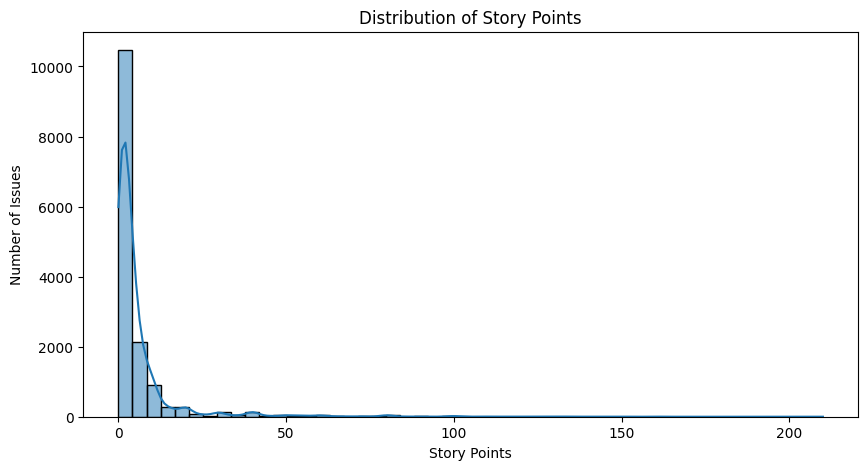

In [7]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))
sns.histplot(df["Story_Point"], bins=50, kde=True)

plt.title("Distribution of Story Points")
plt.xlabel("Story Points")
plt.ylabel("Number of Issues")
plt.show()

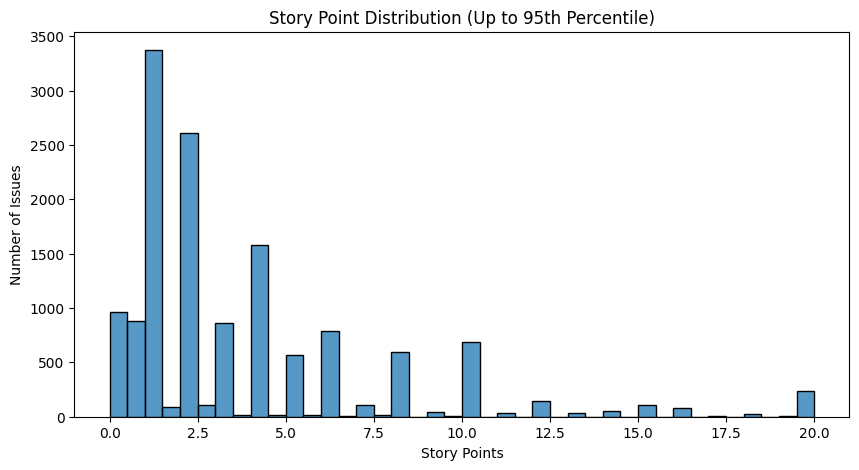

In [8]:
upper_limit = df["Story_Point"].quantile(0.95)

plt.figure(figsize=(10, 5))
sns.histplot(
    df.loc[df["Story_Point"] <= upper_limit, "Story_Point"],
    bins=40
)

plt.title("Story Point Distribution (Up to 95th Percentile)")
plt.xlabel("Story Points")
plt.ylabel("Number of Issues")
plt.show()

In [9]:

print("Zero story points:",
      (df["Story_Point"] == 0).sum())

print("Fractional story points:",
      ((df["Story_Point"] % 1) != 0).sum())

print("\nHighest story points:")
print(df["Story_Point"].nlargest(15).values)

print("\nMost frequent story points:")
print(df["Story_Point"].value_counts().head(20))

Zero story points: 417
Fractional story points: 1932

Highest story points:
[210. 200. 195. 190. 185. 172. 168. 160. 160. 160. 160. 151. 150. 150.
 144.]

Most frequent story points:
Story_Point
1.00     3233
2.00     2602
4.00     1566
3.00      856
0.50      803
6.00      783
10.00     684
8.00      597
5.00      560
0.00      417
20.00     240
0.25      212
0.10      147
12.00     145
40.00     131
1.40      116
15.00     108
30.00     107
7.00      106
1.50       76
Name: count, dtype: int64


In [10]:

print("Estimation dates before creation:",
      (df["Estimation_Date"] < df["Creation_Date"]).sum())

print("Estimation dates equal to creation:",
      (df["Estimation_Date"] == df["Creation_Date"]).sum())

print("Estimation dates after creation:",
      (df["Estimation_Date"] > df["Creation_Date"]).sum())

print("\nSample records:")
print(
    df[[
        "Issue_Key",
        "Creation_Date",
        "Estimation_Date",
        "Story_Point"
    ]].head(15).to_string(index=False)
)


Estimation dates before creation: 0
Estimation dates equal to creation: 14782
Estimation dates after creation: 0

Sample records:
Issue_Key       Creation_Date     Estimation_Date  Story_Point
     DM-8 2014-03-04 14:51:50 2014-03-04 14:51:50          2.0
     DM-9 2014-03-05 09:49:35 2014-03-05 09:49:35          1.0
    DM-10 2014-03-05 10:43:43 2014-03-05 10:43:43         10.0
    DM-17 2014-03-06 17:03:11 2014-03-06 17:03:11         10.0
    DM-21 2014-03-07 15:27:33 2014-03-07 15:27:33          1.0
    DM-25 2014-03-07 15:31:31 2014-03-07 15:31:31          1.0
    DM-26 2014-03-07 15:34:32 2014-03-07 15:34:32          1.0
    DM-55 2014-03-07 21:58:34 2014-03-07 21:58:34         15.0
    DM-70 2014-03-07 22:35:20 2014-03-07 22:35:20         30.0
    DM-75 2014-03-08 19:24:09 2014-03-08 19:24:09          1.0
    DM-78 2014-03-11 10:48:10 2014-03-11 10:48:10          1.0
    DM-83 2014-03-11 16:01:17 2014-03-11 16:01:17          4.0
    DM-90 2014-03-12 11:32:59 2014-03-12 11:32:59  

In [11]:

for i in range(5):
    print(f"\nISSUE {i+1}")
    print("Text:", repr(df.loc[i, "Text"][:500]))
    print("Story Point:", df.loc[i, "Story_Point"])



ISSUE 1
Text: "'Finalize DM mission statement' '''The proposed mission statement for the LSST Software Stack development: {quote} Enabling LSST science by creating a well documented  state-of-the-art  high-performance  scalable  multi-camera  open source  O/IR survey data processing and analysis system {quote} with the following rationale:  * well documented -- as otherwise it will be impossible to maintain or be usable for Level 3 * state-of-the-art -- because the quality of the instrument and needs of the sc"
Story Point: 2.0

ISSUE 2
Text: "'Open up LSST software mailing lists' '''We all benefit from making LSST software development as open as possible and conducive to outside volunteer contributions (*). One way to increase community involvement is to open up our development mailing lists to the public  analogous to the way other open source projects do. For example  we could have:  * <EMAIL>: the development mailing list  equivalent to current lsst-data * <EMAIL>: the users maili

In [12]:
import re

def clean_boundary_quotes(text):
    text = str(text)
    text = re.sub(r"^['\"]+", "", text)
    text = re.sub(r"['\"]+$", "", text)
    return text.strip()

df["Title"] = df["Title"].apply(clean_boundary_quotes)

df["Description_Text"] = (
    df["Description_Text"]
    .fillna("")
    .apply(clean_boundary_quotes)
)

df["Text"] = (
    df["Title"] + " " + df["Description_Text"]
).str.strip()

print(df["Text"].head(5).to_list())

["Finalize DM mission statement The proposed mission statement for the LSST Software Stack development: {quote} Enabling LSST science by creating a well documented  state-of-the-art  high-performance  scalable  multi-camera  open source  O/IR survey data processing and analysis system {quote} with the following rationale:  * well documented -- as otherwise it will be impossible to maintain or be usable for Level 3 * state-of-the-art -- because the quality of the instrument and needs of the science to be systematic limited require us to develop new algorithms an break new ground in a number of areas * high-performance -- because of the massive amount of data we need to process for a reasonable budget * scalable -- because we need it to run from between a single core (for developers  or Level 3 users) to tens of thousands of cores (for Data Release production) * multi-camera -- because we need to process precursor data for development purposes  and because our as-delivered camera won't b

In [13]:
df = df.sort_values(
    "Creation_Date"
).reset_index(drop=True)

In [14]:
cutoff_date = df["Creation_Date"].quantile(0.80)

development_df = df[
    df["Creation_Date"] < cutoff_date
].copy()

test_df = df[
    df["Creation_Date"] >= cutoff_date
].copy()

print("Cutoff date:", cutoff_date)

print("Development size:", len(development_df))
print("Test size:", len(test_df))

print("\nDevelopment date range:")
print(development_df["Creation_Date"].min())
print(development_df["Creation_Date"].max())

print("\nTest date range:")
print(test_df["Creation_Date"].min())
print(test_df["Creation_Date"].max())

Cutoff date: 2019-11-07 22:48:58.200000
Development size: 11825
Test size: 2957

Development date range:
2014-03-04 14:51:50
2019-11-07 22:44:03

Test date range:
2019-11-07 22:50:12
2020-10-22 14:51:07


In [15]:
from sklearn.model_selection import TimeSeriesSplit

splitter = TimeSeriesSplit(n_splits=5)

folds = []

for fold_number, (train_idx, val_idx) in enumerate(
    splitter.split(development_df), start=1
):
    train_fold = development_df.iloc[train_idx].copy()
    val_fold = development_df.iloc[val_idx].copy()

    folds.append((train_fold, val_fold))

    print(f"\nFOLD {fold_number}")
    print("Training:", len(train_fold))
    print("Validation:", len(val_fold))
    print("Training end:", train_fold["Creation_Date"].max())
    print("Validation start:", val_fold["Creation_Date"].min())



FOLD 1
Training: 1975
Validation: 1970
Training end: 2016-02-04 18:51:39
Validation start: 2016-02-04 23:01:38

FOLD 2
Training: 3945
Validation: 1970
Training end: 2016-12-01 19:22:15
Validation start: 2016-12-01 20:46:12

FOLD 3
Training: 5915
Validation: 1970
Training end: 2017-10-05 13:45:16
Validation start: 2017-10-05 14:38:38

FOLD 4
Training: 7885
Validation: 1970
Training end: 2018-08-08 16:34:07
Validation start: 2018-08-08 17:27:14

FOLD 5
Training: 9855
Validation: 1970
Training end: 2019-04-08 12:41:48
Validation start: 2019-04-08 12:41:58


In [16]:
for i, (train_fold, val_fold) in enumerate(folds):

    print(f"\nFOLD {i+1}")

    print("Training date range:")
    print(train_fold["Creation_Date"].min(),
          "to",
          train_fold["Creation_Date"].max())

    print("Validation date range:")
    print(val_fold["Creation_Date"].min(),
          "to",
          val_fold["Creation_Date"].max())


FOLD 1
Training date range:
2014-03-04 14:51:50 to 2016-02-04 18:51:39
Validation date range:
2016-02-04 23:01:38 to 2016-12-01 19:22:15

FOLD 2
Training date range:
2014-03-04 14:51:50 to 2016-12-01 19:22:15
Validation date range:
2016-12-01 20:46:12 to 2017-10-05 13:45:16

FOLD 3
Training date range:
2014-03-04 14:51:50 to 2017-10-05 13:45:16
Validation date range:
2017-10-05 14:38:38 to 2018-08-08 16:34:07

FOLD 4
Training date range:
2014-03-04 14:51:50 to 2018-08-08 16:34:07
Validation date range:
2018-08-08 17:27:14 to 2019-04-08 12:41:48

FOLD 5
Training date range:
2014-03-04 14:51:50 to 2019-04-08 12:41:48
Validation date range:
2019-04-08 12:41:58 to 2019-11-07 22:44:03


In [17]:
import os

os.makedirs("folds", exist_ok=True)

for i, (train_fold, val_fold) in enumerate(folds):

    train_fold.to_csv(
        f"folds/train_fold_{i+1}.csv",
        index=False
    )

    val_fold.to_csv(
        f"folds/val_fold_{i+1}.csv",
        index=False
    )

print("All five folds saved!")

All five folds saved!


In [18]:

!pip install -q transformers

In [19]:

import torch
from transformers import BertTokenizer, BertModel

MODEL_NAME = "bert-base-uncased"

# Load tokenizer
tokenizer = BertTokenizer.from_pretrained(MODEL_NAME)

# Load pretrained BERT
bert_model = BertModel.from_pretrained(MODEL_NAME)

# Select device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

bert_model = bert_model.to(device)

# Freeze BERT parameters
for param in bert_model.parameters():
    param.requires_grad = False

bert_model.eval()

print("BERT loaded successfully!")
print("Device:", device)
print("Hidden size:", bert_model.config.hidden_size)
print("Number of layers:", bert_model.config.num_hidden_layers)

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BERT loaded successfully!
Device: cuda
Hidden size: 768
Number of layers: 12


In [20]:
sample_text = development_df.iloc[0]["Text"]

tokens = tokenizer.tokenize(sample_text)

print("Original text:")
print(sample_text)

print("\nBERT tokens:")
print(tokens[:50])

print("\nNumber of tokens:")
print(len(tokens))

Original text:
Finalize DM mission statement The proposed mission statement for the LSST Software Stack development: {quote} Enabling LSST science by creating a well documented  state-of-the-art  high-performance  scalable  multi-camera  open source  O/IR survey data processing and analysis system {quote} with the following rationale:  * well documented -- as otherwise it will be impossible to maintain or be usable for Level 3 * state-of-the-art -- because the quality of the instrument and needs of the science to be systematic limited require us to develop new algorithms an break new ground in a number of areas * high-performance -- because of the massive amount of data we need to process for a reasonable budget * scalable -- because we need it to run from between a single core (for developers  or Level 3 users) to tens of thousands of cores (for Data Release production) * multi-camera -- because we need to process precursor data for development purposes  and because our as-delivered c

In [21]:
encoding = tokenizer(
    sample_text,
    max_length=128,
    padding="max_length",
    truncation=True,
    return_tensors="pt"
)

input_ids = encoding["input_ids"].to(device)
attention_mask = encoding["attention_mask"].to(device)

print("Input IDs shape:", input_ids.shape)
print("Attention mask shape:", attention_mask.shape)

print("\nFirst 20 token IDs:")
print(input_ids[0][:20])

print("\nFirst 20 attention mask values:")
print(attention_mask[0][:20])

Input IDs shape: torch.Size([1, 128])
Attention mask shape: torch.Size([1, 128])

First 20 token IDs:
tensor([ 101, 2345, 4697, 1040, 2213, 3260, 4861, 1996, 3818, 3260, 4861, 2005,
        1996, 1048, 4757, 2102, 4007, 9991, 2458, 1024], device='cuda:0')

First 20 attention mask values:
tensor([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
       device='cuda:0')


In [22]:
with torch.no_grad():

    outputs = bert_model(
        input_ids=input_ids,
        attention_mask=attention_mask
    )

embeddings = outputs.last_hidden_state

print("BERT embedding shape:", embeddings.shape)

BERT embedding shape: torch.Size([1, 128, 768])


In [23]:
from torch.utils.data import Dataset, DataLoader
import torch

class IssueDataset(Dataset):
    def __init__(self, texts, tokenizer, max_length=128):
        self.texts = texts
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        return self.tokenizer(
            str(self.texts[idx]),
            max_length=self.max_length,
            padding="max_length",
            truncation=True,
            return_tensors="pt"
        )

# Start with a small batch size
BATCH_SIZE = 16

dataset = IssueDataset(
    development_df["Text"].tolist(),
    tokenizer
)

dataloader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Number of issues:", len(dataset))
print("Number of batches:", len(dataloader))

Number of issues: 11825
Number of batches: 740


In [24]:

import numpy as np
import torch
import gc

# Create a disk-backed array (float16)
embedding_file = np.lib.format.open_memmap(
    "development_embeddings.npy",
    mode="w+",
    dtype=np.float16,
    shape=(len(development_df), 128, 768)
)

bert_model.eval()
start = 0

with torch.no_grad():
    for batch_idx, batch in enumerate(dataloader):

        input_ids = batch["input_ids"].squeeze(1).to(device)
        attention_mask = batch["attention_mask"].squeeze(1).to(device)

        outputs = bert_model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        batch_embeddings = outputs.last_hidden_state

        end = start + batch_embeddings.shape[0]

        # Save this batch directly to disk
        embedding_file[start:end] = (
            batch_embeddings.cpu().numpy().astype(np.float16)
        )

        start = end

        del outputs, batch_embeddings, input_ids, attention_mask

        if (batch_idx + 1) % 50 == 0:
            embedding_file.flush()
            print(f"Saved {start}/{len(development_df)} issues")

        if (batch_idx + 1) % 100 == 0:
            torch.cuda.empty_cache()
            gc.collect()

embedding_file.flush()

print("All development embeddings saved!")
print("Shape:", embedding_file.shape)
print("Data type:", embedding_file.dtype)


Saved 800/11825 issues
Saved 1600/11825 issues
Saved 2400/11825 issues
Saved 3200/11825 issues
Saved 4000/11825 issues
Saved 4800/11825 issues
Saved 5600/11825 issues
Saved 6400/11825 issues
Saved 7200/11825 issues
Saved 8000/11825 issues
Saved 8800/11825 issues
Saved 9600/11825 issues
Saved 10400/11825 issues
Saved 11200/11825 issues
All development embeddings saved!
Shape: (11825, 128, 768)
Data type: float16


In [25]:

np.save(
    "development_labels.npy",
    development_df["Story_Point"].values.astype(np.float32)
)

print("Labels saved!")


Labels saved!


In [26]:

import numpy as np
import os

# Load embeddings as a memory-mapped array
dev_embeddings = np.load(
    "development_embeddings.npy",
    mmap_mode="r"
)

dev_labels = np.load("development_labels.npy")

print("Embeddings shape:", dev_embeddings.shape)
print("Embeddings dtype:", dev_embeddings.dtype)
print("Labels shape:", dev_labels.shape)
print("Embedding file size (GB):",
      round(os.path.getsize("development_embeddings.npy") / (1024**3), 2))
print("Labels file size (MB):",
      round(os.path.getsize("development_labels.npy") / (1024**2), 2))

print("First 5 labels:", dev_labels[:5])


Embeddings shape: (11825, 128, 768)
Embeddings dtype: float16
Labels shape: (11825,)
Embedding file size (GB): 2.17
Labels file size (MB): 0.05
First 5 labels: [ 2.  1. 10. 10.  1.]


In [27]:

test_dataset = IssueDataset(
    test_df["Text"].tolist(),
    tokenizer
)

test_dataloader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False
)

print("Test issues:", len(test_dataset))
print("Test batches:", len(test_dataloader))


Test issues: 2957
Test batches: 185


In [28]:

test_embedding_file = np.lib.format.open_memmap(
    "test_embeddings.npy",
    mode="w+",
    dtype=np.float16,
    shape=(len(test_df), 128, 768)
)

bert_model.eval()
start = 0

with torch.no_grad():
    for batch_idx, batch in enumerate(test_dataloader):

        input_ids = batch["input_ids"].squeeze(1).to(device)
        attention_mask = batch["attention_mask"].squeeze(1).to(device)

        outputs = bert_model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        batch_embeddings = outputs.last_hidden_state
        end = start + batch_embeddings.shape[0]

        test_embedding_file[start:end] = (
            batch_embeddings.cpu().numpy().astype(np.float16)
        )

        start = end

        del outputs, batch_embeddings, input_ids, attention_mask

        if (batch_idx + 1) % 50 == 0:
            test_embedding_file.flush()
            print(f"Saved {start}/{len(test_df)} test issues")

        if (batch_idx + 1) % 100 == 0:
            torch.cuda.empty_cache()
            gc.collect()

test_embedding_file.flush()

print("Test embeddings saved!")
print("Shape:", test_embedding_file.shape)


Saved 800/2957 test issues
Saved 1600/2957 test issues
Saved 2400/2957 test issues
Test embeddings saved!
Shape: (2957, 128, 768)


In [29]:

np.save(
    "test_labels.npy",
    test_df["Story_Point"].values.astype(np.float32)
)

print("Test labels saved!")


Test labels saved!


In [30]:

test_embeddings = np.load("test_embeddings.npy", mmap_mode="r")
test_labels = np.load("test_labels.npy")

print("Test embeddings:", test_embeddings.shape)
print("Test labels:", test_labels.shape)
print("Embedding dtype:", test_embeddings.dtype)


Test embeddings: (2957, 128, 768)
Test labels: (2957,)
Embedding dtype: float16


In [31]:
from sklearn.model_selection import TimeSeriesSplit
import numpy as np

splitter = TimeSeriesSplit(n_splits=5)
fold_indices = list(splitter.split(np.arange(len(dev_labels))))

for fold_number, (train_idx, val_idx) in enumerate(fold_indices, start=1):
    print(f"Fold {fold_number}")
    print("Training issues:", len(train_idx))
    print("Validation issues:", len(val_idx))
    print("Training ends before validation:", train_idx[-1] < val_idx[0])
    print("-" * 30)


Fold 1
Training issues: 1975
Validation issues: 1970
Training ends before validation: True
------------------------------
Fold 2
Training issues: 3945
Validation issues: 1970
Training ends before validation: True
------------------------------
Fold 3
Training issues: 5915
Validation issues: 1970
Training ends before validation: True
------------------------------
Fold 4
Training issues: 7885
Validation issues: 1970
Training ends before validation: True
------------------------------
Fold 5
Training issues: 9855
Validation issues: 1970
Training ends before validation: True
------------------------------


In [32]:

import torch
import torch.nn as nn

class StoryPointCNN(nn.Module):
    def __init__(self):
        super(StoryPointCNN, self).__init__()

        self.conv_layers = nn.Sequential(
            nn.Conv1d(768, 256, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.Conv1d(256, 128, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.Conv1d(128, 64, kernel_size=3, padding=1),
            nn.ReLU()
        )

        self.pool = nn.AdaptiveMaxPool1d(1)

        self.regressor = nn.Linear(64, 1)

    def forward(self, x):
        # (batch, 128, 768) -> (batch, 768, 128)
        x = x.transpose(1, 2)

        x = self.conv_layers(x)

        x = self.pool(x)

        x = x.squeeze(-1)

        x = self.regressor(x)

        return x.squeeze(1)


model = StoryPointCNN().to(device)

print(model)


StoryPointCNN(
  (conv_layers): Sequential(
    (0): Conv1d(768, 256, kernel_size=(3,), stride=(1,), padding=(1,))
    (1): ReLU()
    (2): Conv1d(256, 128, kernel_size=(3,), stride=(1,), padding=(1,))
    (3): ReLU()
    (4): Conv1d(128, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (5): ReLU()
  )
  (pool): AdaptiveMaxPool1d(output_size=1)
  (regressor): Linear(in_features=64, out_features=1, bias=True)
)


In [33]:

# Take one batch of embeddings
sample_input = torch.randn(16, 128, 768).to(device)

# Pass through CNN
with torch.no_grad():
    sample_output = model(sample_input)

print("Input shape:", sample_input.shape)
print("Output shape:", sample_output.shape)
print("Sample predictions:", sample_output[:5])


Input shape: torch.Size([16, 128, 768])
Output shape: torch.Size([16])
Sample predictions: tensor([-0.1013, -0.1012, -0.1131, -0.1344, -0.1186], device='cuda:0')


In [34]:

from torch.utils.data import Dataset, DataLoader
import numpy as np

class EmbeddingDataset(Dataset):
    def __init__(self, embeddings, labels):
        self.embeddings = embeddings
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        x = torch.from_numpy(
            self.embeddings[idx].astype(np.float32)
        )
        y = torch.tensor(self.labels[idx], dtype=torch.float32)
        return x, y


# Memory-mapped embeddings
dev_embeddings = np.load(
    "development_embeddings.npy",
    mmap_mode="r"
)

dev_labels = np.load("development_labels.npy")

# Create dataset
dev_dataset = EmbeddingDataset(
    dev_embeddings,
    dev_labels
)

print("Dataset size:", len(dev_dataset))

# Check one sample
sample_x, sample_y = dev_dataset[0]

print("Input shape:", sample_x.shape)
print("Target:", sample_y)


Dataset size: 11825
Input shape: torch.Size([128, 768])
Target: tensor(2.)


In [35]:

from torch.utils.data import Subset, DataLoader

# Get Fold 1 indices
train_idx, val_idx = fold_indices[0]

train_dataset = Subset(dev_dataset, train_idx)
val_dataset = Subset(dev_dataset, val_idx)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False
)

# Calculate normalization using training labels only
train_targets = dev_labels[train_idx]

target_mean = train_targets.mean()
target_std = train_targets.std()

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Target mean:", target_mean)
print("Target standard deviation:", target_std)


Training samples: 1975
Validation samples: 1970
Target mean: 5.566766
Target standard deviation: 11.039141


In [36]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
from torch.utils.data import Subset, DataLoader


def train_one_fold(train_idx, val_idx, fold_number, epochs=25, patience=5):
    torch.manual_seed(42 + fold_number)

    train_dataset = Subset(dev_dataset, train_idx)
    val_dataset = Subset(dev_dataset, val_idx)
    train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

    train_targets = dev_labels[train_idx]
    target_center = float(np.median(train_targets))
    target_scale = float(
        np.quantile(train_targets, 0.75) - np.quantile(train_targets, 0.25)
    )
    if target_scale <= 0:
        target_scale = 1.0

    model = StoryPointCNN().to(device)
    criterion = nn.L1Loss()
    optimizer = optim.AdamW(model.parameters(), lr=0.0005, weight_decay=1e-4)

    best_mae = float("inf")
    best_epoch = 0
    best_state = None
    epochs_without_improvement = 0

    for epoch in range(epochs):
        model.train()
        total_train_loss = 0.0

        for X, y in train_loader:
            X = X.to(device)
            y = (y.to(device) - target_center) / target_scale

            optimizer.zero_grad()
            predictions = model(X)
            loss = criterion(predictions, y)
            loss.backward()
            optimizer.step()
            total_train_loss += loss.item() * X.size(0)

        model.eval()
        val_predictions = []
        with torch.no_grad():
            for X, _ in val_loader:
                predictions = model(X.to(device)).cpu().numpy()
                predictions = np.maximum(
                    0.0, predictions * target_scale + target_center
                )
                val_predictions.extend(predictions)

        actual_values = dev_labels[val_idx]
        val_mae = float(np.mean(np.abs(actual_values - val_predictions)))
        avg_train_loss = total_train_loss / len(train_dataset)
        print(
            f"Fold {fold_number} | Epoch {epoch + 1}/{epochs} | "
            f"Train L1: {avg_train_loss:.4f} | Val MAE: {val_mae:.4f}"
        )

        if val_mae < best_mae:
            best_mae = val_mae
            best_epoch = epoch + 1
            best_state = {
                name: value.detach().cpu().clone()
                for name, value in model.state_dict().items()
            }
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= patience:
                print(f"Early stopping after epoch {epoch + 1}")
                break

    if best_state is None:
        raise RuntimeError(f"Fold {fold_number} did not produce a checkpoint")

    model.load_state_dict(best_state)
    model.eval()
    predicted_values = []
    with torch.no_grad():
        for X, _ in val_loader:
            predictions = model(X.to(device)).cpu().numpy()
            predictions = np.maximum(
                0.0, predictions * target_scale + target_center
            )
            predicted_values.extend(predictions)

    actual_values = dev_labels[val_idx]
    mae = float(np.mean(np.abs(actual_values - predicted_values)))
    mdae = float(np.median(np.abs(actual_values - predicted_values)))
    print(
        f"\nFold {fold_number} best epoch: {best_epoch} | "
        f"MAE: {mae:.4f} | MdAE: {mdae:.4f}\n"
    )
    return mae, mdae, model, best_epoch


fold_results = []
for fold_number, (train_idx, val_idx) in enumerate(fold_indices, start=1):
    print(f"\n========== FOLD {fold_number} ==========")
    mae, mdae, trained_model, best_epoch = train_one_fold(
        train_idx, val_idx, fold_number
    )
    fold_results.append({
        "Fold": fold_number,
        "MAE": mae,
        "MdAE": mdae,
        "Best_Epoch": best_epoch,
    })
    del trained_model
    torch.cuda.empty_cache()

print("\n========== CHRONOLOGICAL CROSS-VALIDATION RESULTS ==========")
for result in fold_results:
    print(result)
print("Average MAE:", np.mean([result["MAE"] for result in fold_results]))
print("Average MdAE:", np.mean([result["MdAE"] for result in fold_results]))



========== FOLD 1 ==========
Fold 1 | Epoch 1/25 | Train L1: 0.8299 | Val MAE: 5.0371
Fold 1 | Epoch 2/25 | Train L1: 0.7810 | Val MAE: 4.9290
Fold 1 | Epoch 3/25 | Train L1: 0.7493 | Val MAE: 4.7663
Fold 1 | Epoch 4/25 | Train L1: 0.7008 | Val MAE: 4.7262
Fold 1 | Epoch 5/25 | Train L1: 0.6747 | Val MAE: 4.6985
Fold 1 | Epoch 6/25 | Train L1: 0.6218 | Val MAE: 4.7158
Fold 1 | Epoch 7/25 | Train L1: 0.5769 | Val MAE: 4.7332
Fold 1 | Epoch 8/25 | Train L1: 0.5308 | Val MAE: 4.6669
Fold 1 | Epoch 9/25 | Train L1: 0.4819 | Val MAE: 4.7593
Fold 1 | Epoch 10/25 | Train L1: 0.4403 | Val MAE: 4.8334
Fold 1 | Epoch 11/25 | Train L1: 0.4217 | Val MAE: 4.7655
Fold 1 | Epoch 12/25 | Train L1: 0.3807 | Val MAE: 4.8455
Fold 1 | Epoch 13/25 | Train L1: 0.4028 | Val MAE: 4.7896
Early stopping after epoch 13

Fold 1 best epoch: 8 | MAE: 4.6669 | MdAE: 1.7122


========== FOLD 2 ==========
Fold 2 | Epoch 1/25 | Train L1: 0.8957 | Val MAE: 4.6881
Fold 2 | Epoch 2/25 | Train L1: 0.8330 | Val MAE: 4.5282

In [37]:

import pandas as pd

cv_results_df = pd.DataFrame(fold_results)
cv_results_df.to_csv("cv_results.csv", index=False)

print(cv_results_df)
print("\nAverage MAE:", cv_results_df["MAE"].mean())
print("Average MdAE:", cv_results_df["MdAE"].mean())


   Fold       MAE      MdAE  Best_Epoch
0     1  4.666867  1.712183           8
1     2  4.348128  1.374560           8
2     3  4.409355  1.508227           5
3     4  4.232382  1.402316           3
4     5  3.695825  1.534752           6

Average MAE: 4.270511341094971
Average MdAE: 1.5064076423645019


In [38]:
# Use all development issues for final training
final_train_loader = DataLoader(
    dev_dataset,
    batch_size=32,
    shuffle=True
)

test_embeddings = np.load(
    "test_embeddings.npy",
    mmap_mode="r"
)
test_labels = np.load("test_labels.npy")
test_dataset = EmbeddingDataset(test_embeddings, test_labels)
final_test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

# Use robust label scaling, computed from the development set only.
final_center = float(np.median(dev_labels))
final_scale = float(
    np.quantile(dev_labels, 0.75) - np.quantile(dev_labels, 0.25)
)
if final_scale <= 0:
    final_scale = 1.0

print("Final training samples:", len(dev_dataset))
print("Final test samples:", len(test_dataset))


Final training samples: 11825
Final test samples: 2957


In [39]:
# Refit using the median best epoch selected by chronological CV.
torch.manual_seed(42)
final_model = StoryPointCNN().to(device)
criterion = nn.L1Loss()
optimizer = optim.AdamW(final_model.parameters(), lr=0.0005, weight_decay=1e-4)
FINAL_EPOCHS = max(
    1, int(round(float(np.median([result["Best_Epoch"] for result in fold_results]))))
)

for epoch in range(FINAL_EPOCHS):
    final_model.train()
    total_loss = 0.0

    for X, y in final_train_loader:
        X = X.to(device)
        y = (y.to(device) - final_center) / final_scale

        optimizer.zero_grad()
        predictions = final_model(X)
        loss = criterion(predictions, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * X.size(0)

    avg_loss = total_loss / len(dev_dataset)
    print(
        f"Epoch {epoch + 1}/{FINAL_EPOCHS} "
        f"| Training L1: {avg_loss:.4f}"
    )

print("Final model training completed!")


Epoch 1/6 | Training L1: 0.8781
Epoch 2/6 | Training L1: 0.8149
Epoch 3/6 | Training L1: 0.7754
Epoch 4/6 | Training L1: 0.7386
Epoch 5/6 | Training L1: 0.7038
Epoch 6/6 | Training L1: 0.6690
Final model training completed!


In [40]:
final_model.eval()
actual_values = []
predicted_values = []

with torch.no_grad():
    for X, y in final_test_loader:
        predictions = final_model(X.to(device)).cpu().numpy()
        predictions = np.maximum(
            0.0, predictions * final_scale + final_center
        )
        predicted_values.extend(predictions)
        actual_values.extend(y.numpy())

actual_values = np.asarray(actual_values)
predicted_values = np.asarray(predicted_values)
test_mae = float(np.mean(np.abs(actual_values - predicted_values)))
test_mdae = float(np.median(np.abs(actual_values - predicted_values)))

print("FINAL TEST RESULTS")
print("-------------------")
print("Test MAE:", round(test_mae, 4))
print("Test MdAE:", round(test_mdae, 4))


FINAL TEST RESULTS
-------------------
Test MAE: 3.6281
Test MdAE: 1.0887


In [41]:
import pandas as pd
import torch

torch.save(final_model.state_dict(), "bert_cnn_final_model.pth")

predictions_df = pd.DataFrame({
    "Actual_Story_Point": actual_values,
    "Predicted_Story_Point": predicted_values,
    "Absolute_Error": np.abs(actual_values - predicted_values),
})
predictions_df.to_csv("test_predictions.csv", index=False)

results_df = pd.DataFrame([
    {"Metric": "Average CV MAE", "Value": float(cv_results_df["MAE"].mean())},
    {"Metric": "Average CV MdAE", "Value": float(cv_results_df["MdAE"].mean())},
    {"Metric": "Test MAE", "Value": test_mae},
    {"Metric": "Test MdAE", "Value": test_mdae},
])
results_df.to_csv("final_results.csv", index=False)

print("Saved model, test_predictions.csv, and final_results.csv")


Saved model, test_predictions.csv, and final_results.csv


In [42]:

import numpy as np
import pandas as pd

# Baseline prediction: development-set median
baseline_prediction = np.median(dev_labels)

print("Development median story point:", baseline_prediction)

# Five-fold cross-validation baseline
baseline_cv_results = []

for fold_number, (train_idx, val_idx) in enumerate(fold_indices, start=1):

    # Calculate median using only that fold's training labels
    train_median = np.median(dev_labels[train_idx])

    actual = dev_labels[val_idx]

    # Predict the same median for every validation issue
    predicted = np.full(len(actual), train_median)

    mae = np.mean(np.abs(actual - predicted))
    mdae = np.median(np.abs(actual - predicted))

    baseline_cv_results.append({
        "Fold": fold_number,
        "MAE": mae,
        "MdAE": mdae
    })

baseline_cv_df = pd.DataFrame(baseline_cv_results)

print("\nBASELINE CROSS-VALIDATION RESULTS")
print(baseline_cv_df)

print("\nAverage Baseline MAE:",
      baseline_cv_df["MAE"].mean())

print("Average Baseline MdAE:",
      baseline_cv_df["MdAE"].mean())


Development median story point: 2.0

BASELINE CROSS-VALIDATION RESULTS
   Fold       MAE  MdAE
0     1  5.401531   1.9
1     2  5.197982   2.0
2     3  5.461881   1.5
3     4  5.020512   1.0
4     5  4.360227   1.0

Average Baseline MAE: 5.088427
Average Baseline MdAE: 1.48


In [43]:

# Median calculated from the entire development set
final_baseline_prediction = np.median(dev_labels)

# Predict the same value for all test issues
baseline_test_predictions = np.full(
    len(test_labels),
    final_baseline_prediction
)

baseline_test_mae = np.mean(
    np.abs(test_labels - baseline_test_predictions)
)

baseline_test_mdae = np.median(
    np.abs(test_labels - baseline_test_predictions)
)

print("BASELINE TEST RESULTS")
print("---------------------")
print("Baseline prediction:", final_baseline_prediction)
print("Test MAE:", round(float(baseline_test_mae), 4))
print("Test MdAE:", round(float(baseline_test_mdae), 4))


BASELINE TEST RESULTS
---------------------
Baseline prediction: 2.0
Test MAE: 4.5224
Test MdAE: 1.0


## Additional text-aware baseline

This TF-IDF + Ridge model is tuned only on chronological development folds and is evaluated once on the held-out temporal test set.

In [44]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, median_absolute_error

alpha_candidates = [1.0, 10.0, 50.0, 100.0]
tfidf_cv_results = []

for alpha in alpha_candidates:
    fold_actual = []
    fold_predictions = []
    fold_median_predictions = []

    for train_idx, val_idx in fold_indices:
        train_text = development_df.iloc[train_idx]["Text"].fillna("").astype(str)
        val_text = development_df.iloc[val_idx]["Text"].fillna("").astype(str)
        train_targets = dev_labels[train_idx]
        val_targets = dev_labels[val_idx]

        vectorizer = TfidfVectorizer(
            ngram_range=(1, 2),
            min_df=2,
            max_features=150000,
            sublinear_tf=True,
        )
        train_features = vectorizer.fit_transform(train_text)
        val_features = vectorizer.transform(val_text)
        ridge = Ridge(alpha=alpha)
        ridge.fit(train_features, np.log1p(train_targets))
        predictions = np.maximum(0.0, np.expm1(ridge.predict(val_features)))

        fold_actual.extend(val_targets)
        fold_predictions.extend(predictions)
        fold_median_predictions.extend(
            np.full(len(val_targets), np.median(train_targets))
        )

    tfidf_cv_results.append({
        "Alpha": alpha,
        "MAE": mean_absolute_error(fold_actual, fold_predictions),
        "MdAE": median_absolute_error(fold_actual, fold_predictions),
        "Median_Baseline_MAE": mean_absolute_error(
            fold_actual, fold_median_predictions
        ),
        "Median_Baseline_MdAE": median_absolute_error(
            fold_actual, fold_median_predictions
        ),
    })

tfidf_cv_df = pd.DataFrame(tfidf_cv_results)
print("TEMPORAL CV: TF-IDF + RIDGE")
print(tfidf_cv_df.to_string(index=False))
selected_alpha = float(tfidf_cv_df.loc[tfidf_cv_df["MAE"].idxmin(), "Alpha"])
print("Selected alpha:", selected_alpha)

vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    max_features=150000,
    sublinear_tf=True,
)
dev_text = development_df["Text"].fillna("").astype(str)
test_text = test_df["Text"].fillna("").astype(str)
dev_features = vectorizer.fit_transform(dev_text)
test_features = vectorizer.transform(test_text)
tfidf_model = Ridge(alpha=selected_alpha)
tfidf_model.fit(dev_features, np.log1p(dev_labels))
tfidf_predictions = np.maximum(0.0, np.expm1(tfidf_model.predict(test_features)))

tfidf_test_mae = mean_absolute_error(test_labels, tfidf_predictions)
tfidf_test_mdae = median_absolute_error(test_labels, tfidf_predictions)
print("\nFINAL TEMPORAL TEST COMPARISON")
print(pd.DataFrame([
    {"Model": "TF-IDF + Ridge (log1p)", "MAE": tfidf_test_mae, "MdAE": tfidf_test_mdae},
    {"Model": "Development median", "MAE": baseline_test_mae, "MdAE": baseline_test_mdae},
]).to_string(index=False))

tfidf_predictions_df = pd.DataFrame({
    "Actual_Story_Point": test_labels,
    "Predicted_Story_Point": tfidf_predictions,
    "Absolute_Error": np.abs(test_labels - tfidf_predictions),
})
tfidf_predictions_df.to_csv("tfidf_ridge_test_predictions.csv", index=False)

comparison_df = pd.DataFrame([
    {"Model": "BERT-CNN", "MAE": test_mae, "MdAE": test_mdae},
    {"Model": "TF-IDF + Ridge", "MAE": tfidf_test_mae, "MdAE": tfidf_test_mdae},
    {"Model": "Development median", "MAE": baseline_test_mae, "MdAE": baseline_test_mdae},
])
comparison_df.to_csv("test_model_comparison.csv", index=False)


TEMPORAL CV: TF-IDF + RIDGE
 Alpha      MAE     MdAE  Median_Baseline_MAE  Median_Baseline_MdAE
   1.0 4.410042 1.629736             5.088427                  1.75
  10.0 4.707515 1.773873             5.088427                  1.75
  50.0 4.987329 2.008021             5.088427                  1.75
 100.0 5.057498 2.088597             5.088427                  1.75
Selected alpha: 1.0

FINAL TEMPORAL TEST COMPARISON
                 Model      MAE     MdAE
TF-IDF + Ridge (log1p) 4.097692 1.501445
    Development median 4.522360 1.000000


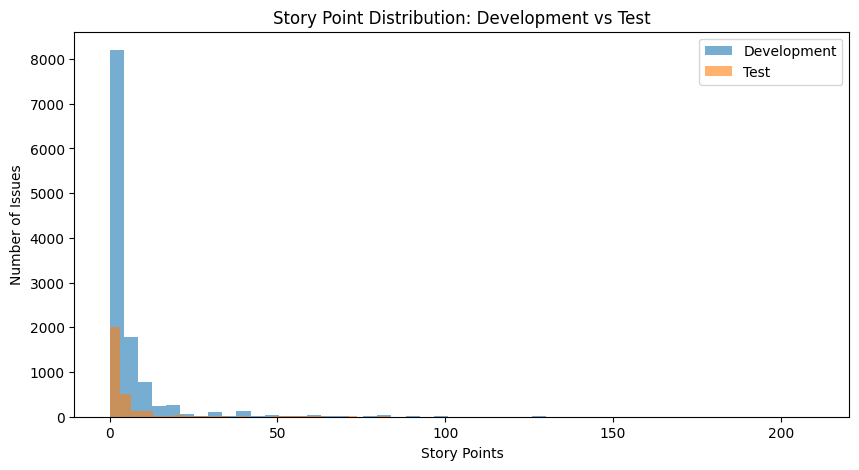

Development median: 2.0
Test median: 2.0
Development mean: 6.124546
Test mean: 5.423443
Development 75th percentile: 6.0
Test 75th percentile: 4.0


In [45]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    dev_labels,
    bins=50,
    alpha=0.6,
    label="Development"
)

plt.hist(
    test_labels,
    bins=50,
    alpha=0.6,
    label="Test"
)

plt.xlabel("Story Points")
plt.ylabel("Number of Issues")
plt.title("Story Point Distribution: Development vs Test")
plt.legend()
plt.show()

print("Development median:", np.median(dev_labels))
print("Test median:", np.median(test_labels))

print("Development mean:", np.mean(dev_labels))
print("Test mean:", np.mean(test_labels))

print("Development 75th percentile:", np.percentile(dev_labels, 75))
print("Test 75th percentile:", np.percentile(test_labels, 75))


In [46]:

print("ACTUAL TEST STATISTICS")
print("Mean:", actual_values.mean())
print("Median:", np.median(actual_values))
print("75th percentile:", np.percentile(actual_values, 75))

print("\nBERT-CNN PREDICTION STATISTICS")
print("Mean:", predicted_values.mean())
print("Median:", np.median(predicted_values))
print("75th percentile:", np.percentile(predicted_values, 75))

print("\nBASELINE PREDICTION STATISTICS")
print("Mean:", baseline_test_predictions.mean())
print("Median:", np.median(baseline_test_predictions))

print("\nBERT-CNN ERROR")
print("Mean error (prediction - actual):",
      np.mean(predicted_values - actual_values))


ACTUAL TEST STATISTICS
Mean: 5.423443
Median: 2.0
75th percentile: 4.0

BERT-CNN PREDICTION STATISTICS
Mean: 3.806481
Median: 1.9181869
75th percentile: 3.0241098

BASELINE PREDICTION STATISTICS
Mean: 2.0
Median: 2.0

BERT-CNN ERROR
Mean error (prediction - actual): -1.616962


In [47]:

# Create a detailed test prediction dataframe
error_analysis = pd.DataFrame({
    "Actual": actual_values,
    "Predicted": predicted_values,
    "Absolute_Error": np.abs(actual_values - predicted_values)
})

# Group actual story points into ranges
error_analysis["Story_Point_Range"] = pd.cut(
    error_analysis["Actual"],
    bins=[-np.inf, 2, 5, 10, 20, np.inf],
    labels=["0-2", "3-5", "6-10", "11-20", "Above 20"]
)

# Calculate errors for each group
group_analysis = error_analysis.groupby(
    "Story_Point_Range",
    observed=False
).agg(
    Number_of_Issues=("Actual", "count"),
    Mean_Actual=("Actual", "mean"),
    Mean_Predicted=("Predicted", "mean"),
    MAE=("Absolute_Error", "mean")
).reset_index()

print(group_analysis)


  Story_Point_Range  Number_of_Issues  Mean_Actual  Mean_Predicted        MAE
0               0-2              1801     1.097862        1.920604   1.082621
1               3-5               569     3.776801        3.554075   2.337573
2              6-10               350     7.723714        4.203362   5.312681
3             11-20                92    15.245218        6.548560  10.242043
4          Above 20               145    53.827652       25.523056  32.046890


In [48]:

# Baseline always predicts 2 story points
error_analysis["Baseline_Prediction"] = 2.0

error_analysis["Baseline_Error"] = np.abs(
    error_analysis["Actual"] -
    error_analysis["Baseline_Prediction"]
)

comparison = error_analysis.groupby(
    "Story_Point_Range",
    observed=False
).agg(
    CNN_MAE=("Absolute_Error", "mean"),
    Baseline_MAE=("Baseline_Error", "mean")
).reset_index()

print(comparison)


  Story_Point_Range    CNN_MAE  Baseline_MAE
0               0-2   1.082621      0.902138
1               3-5   2.337573      1.776801
2              6-10   5.312681      5.723714
3             11-20  10.242043     13.245217
4          Above 20  32.046890     51.827655


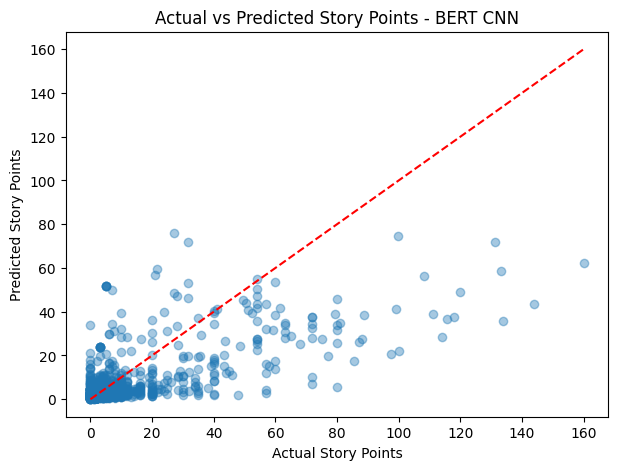

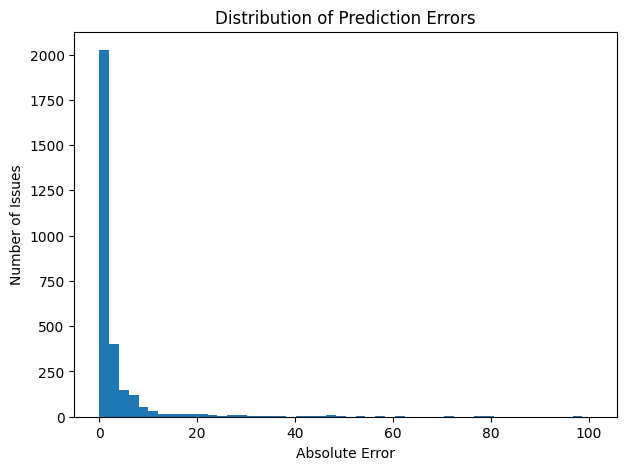

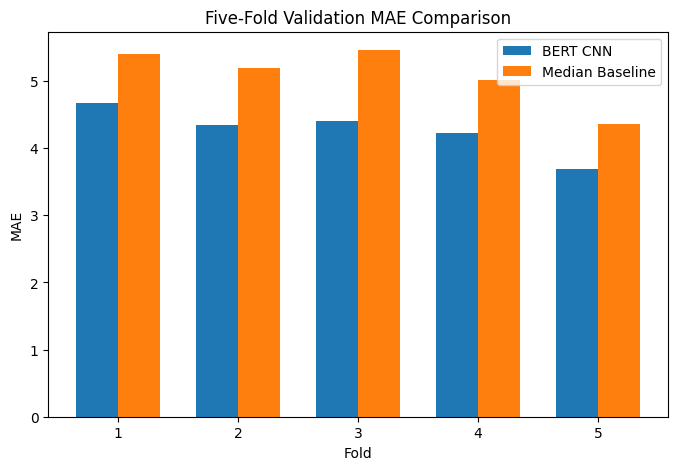

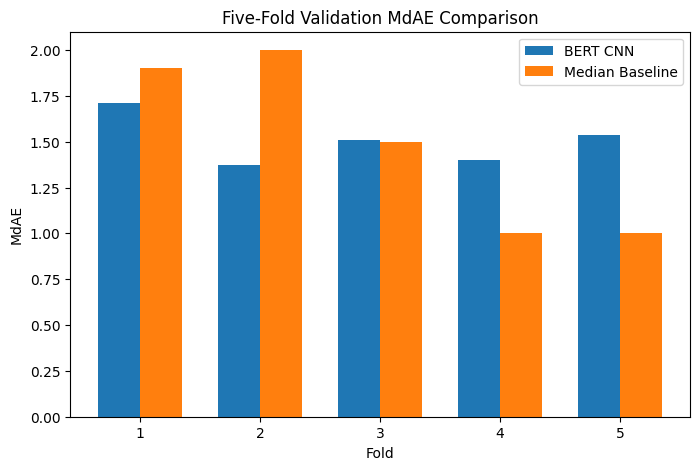

All four plots saved successfully!


In [49]:

import matplotlib.pyplot as plt
import numpy as np

# 1. Actual vs Predicted
plt.figure(figsize=(7, 5))
plt.scatter(actual_values, predicted_values, alpha=0.4)
plt.plot(
    [0, max(actual_values.max(), predicted_values.max())],
    [0, max(actual_values.max(), predicted_values.max())],
    'r--'
)
plt.xlabel("Actual Story Points")
plt.ylabel("Predicted Story Points")
plt.title("Actual vs Predicted Story Points - BERT CNN")
plt.savefig("actual_vs_predicted.png", dpi=300, bbox_inches="tight")
plt.show()


# 2. Absolute error distribution
absolute_errors = np.abs(actual_values - predicted_values)

plt.figure(figsize=(7, 5))
plt.hist(absolute_errors, bins=50)
plt.xlabel("Absolute Error")
plt.ylabel("Number of Issues")
plt.title("Distribution of Prediction Errors")
plt.savefig("error_distribution.png", dpi=300, bbox_inches="tight")
plt.show()


# 3. Cross-validation MAE comparison
fold_numbers = [r["Fold"] for r in fold_results]
cnn_maes = [r["MAE"] for r in fold_results]
baseline_maes = [r["MAE"] for r in baseline_cv_results]

x = np.arange(len(fold_numbers))
width = 0.35

plt.figure(figsize=(8, 5))
plt.bar(x - width/2, cnn_maes, width, label="BERT CNN")
plt.bar(x + width/2, baseline_maes, width, label="Median Baseline")
plt.xticks(x, fold_numbers)
plt.xlabel("Fold")
plt.ylabel("MAE")
plt.title("Five-Fold Validation MAE Comparison")
plt.legend()
plt.savefig("cv_mae_comparison.png", dpi=300, bbox_inches="tight")
plt.show()


# 4. Cross-validation MdAE comparison
cnn_mdaes = [r["MdAE"] for r in fold_results]
baseline_mdaes = [r["MdAE"] for r in baseline_cv_results]

plt.figure(figsize=(8, 5))
plt.bar(x - width/2, cnn_mdaes, width, label="BERT CNN")
plt.bar(x + width/2, baseline_mdaes, width, label="Median Baseline")
plt.xticks(x, fold_numbers)
plt.xlabel("Fold")
plt.ylabel("MdAE")
plt.title("Five-Fold Validation MdAE Comparison")
plt.legend()
plt.savefig("cv_mdae_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

print("All four plots saved successfully!")


### Visualizing Model Performance

The plots below summarize the BERT-CNN predictions and validation results. The actual-versus-predicted scatter plot compares estimates with the ideal prediction line, and the error histogram shows the distribution of prediction mistakes. The remaining charts compare BERT-CNN and median-baseline MAE and MdAE across chronological validation folds; lower values indicate better performance.